In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [4]:
titanic = sns.load_dataset("titanic")

In [5]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
features = ["pclass", "sex", "age", "embarked", "fare"]
target = ["survived"]

In [10]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [13]:
# filling null values
from sklearn.impute import SimpleImputer

si_median = SimpleImputer(strategy="median")
si_frequent = SimpleImputer(strategy="most_frequent")

titanic[["age"]] = si_median.fit_transform(titanic[["age"]])
titanic[["embarked"]] = si_frequent.fit_transform(titanic[["embarked"]])

In [14]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [21]:
X.head()

,pclass,sex,age,embarked,fare
0,3,male,22.0,S,7.2500
1,1,female,38.0,C,71.2833
2,3,female,26.0,S,7.9250
3,1,female,35.0,S,53.1000
4,3,male,35.0,S,8.0500


In [23]:
# encoding
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

titanic["sex"] = le.fit_transform(titanic["sex"])
titanic["embarked"] = le.fit_transform(titanic["embarked"])

In [25]:
# now determine input(X) and output(y)
X = titanic[features]
y = titanic[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [29]:
# model creation
from sklearn.tree import DecisionTreeClassifier, plot_tree

model = DecisionTreeClassifier()
model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [30]:
y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score
print("Accuracy Score: ", accuracy_score(y_test, y_pred))

Accuracy Score:  0.776536312849162


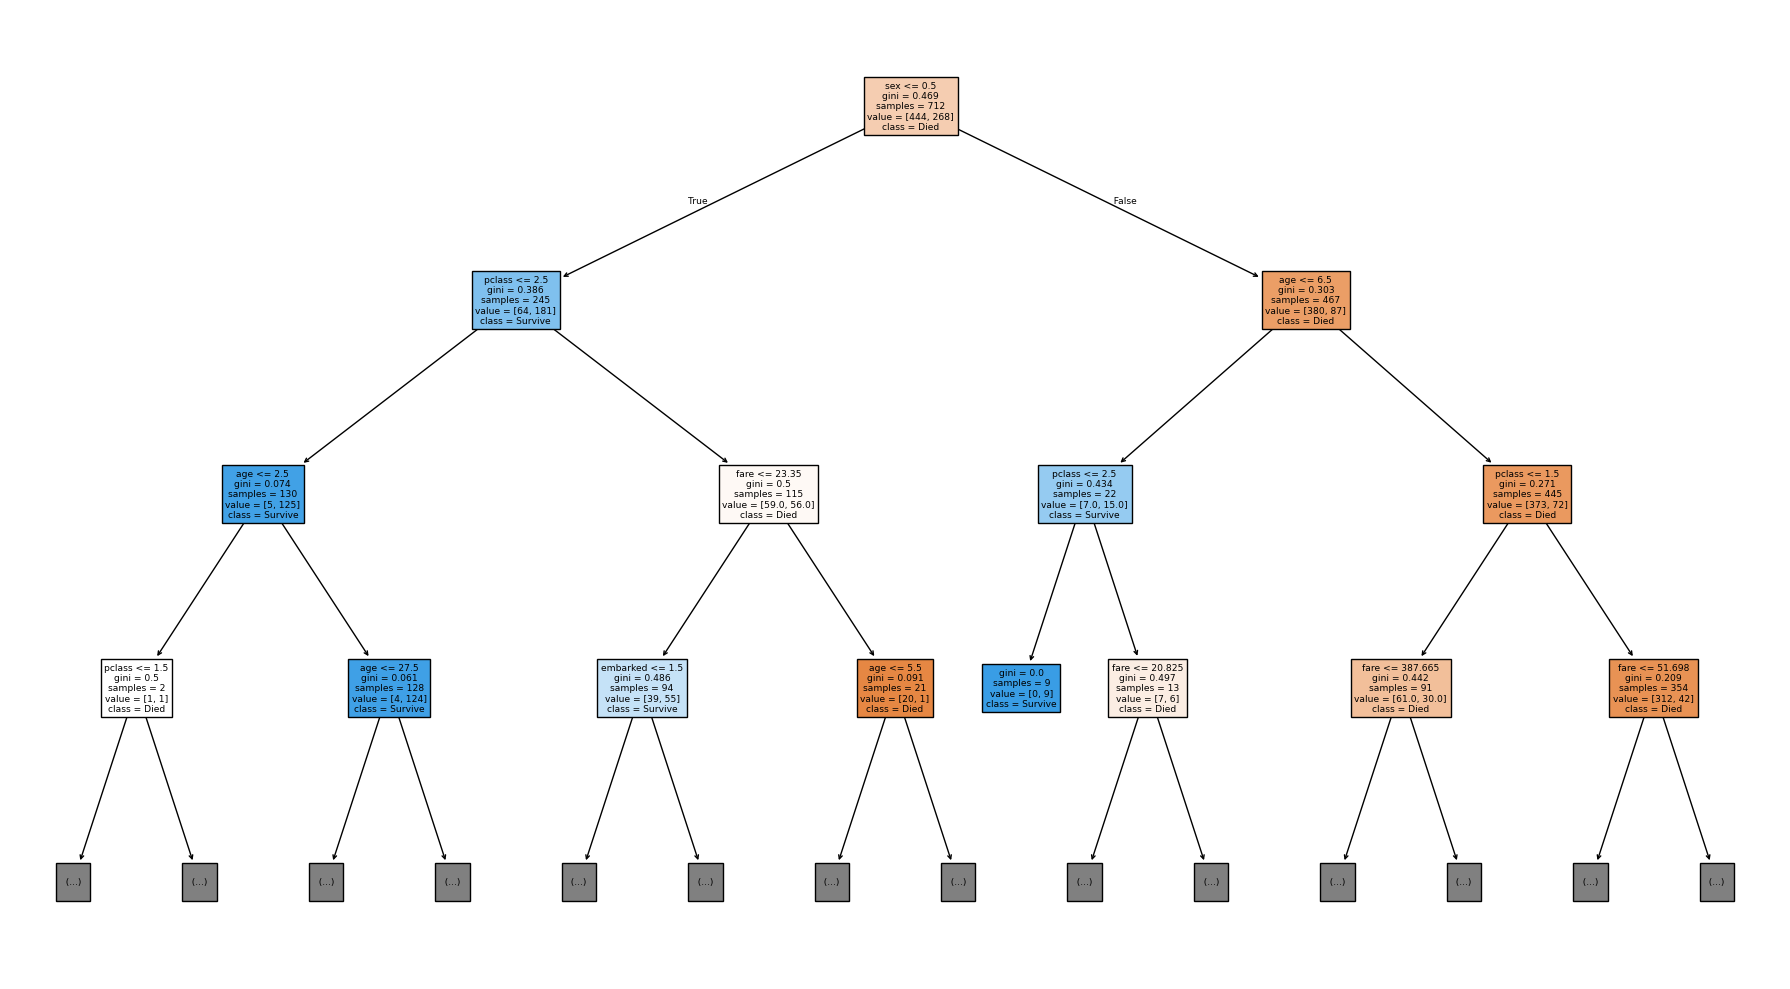

In [35]:
plt.figure(figsize=(18, 10))
plot_tree(model, feature_names=X.columns, class_names=["Died", "Survive"], filled=True, max_depth=3)
plt.tight_layout()
plt.show()